In [112]:
%load_ext autoreload
%autoreload 2
from controller import DeviceMesh, active_mesh, active_stream, Stream, fetch_shard, Future, Stream, get_active_stream
import torch
# this function helps get a local device mesh for testing
from controller._testing import example_mesh, mock_mesh, simulator_mesh
from controller.device_mesh import remote_function
import torch.nn as nn
torch.set_default_device('cuda')

mocked = True
if mocked:
    device_mesh = simulator_mesh(hosts=1, gpus=2, collective_speed=1e4/5)
else:
    device_mesh = example_mesh(hosts=1, gpus=4)
device_mesh.activate()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [113]:
default = get_active_stream()
comms = Stream('comms') # argument is just a debug name

In [114]:
class Layer(nn.Module):
    def __init__(self, dim=1024):
        super().__init__()
        self.w1 = nn.Linear(dim, dim)
        self.w2 = nn.Linear(dim, dim)

    def forward(self, x):
        x = self.w1(x)
        x = self.w2(x)
        return x

In [115]:
# x is on the default stream
def all_gather0(x):
    x = x.reduce('gpu', reduction='stack')
    x = x.view(x.shape[0] * x.shape[1], *x.shape[2:])
    return x


In [139]:
from torch.func import functional_call
from hyperion import explicit_autograd, explicit_module
from torch.utils._pytree import tree_map
def run_fsdp_with_delay(num_layers, fsdp_buffer_size=1):
    device_mesh.ctrl.backend.worker_commands.clear()
    num_layers = 5
    with torch.device('meta'):
        mlp = [Layer() for _ in range(num_layers)]
    
    sharded_state = []
    for layer in mlp:
        state_dict = layer.state_dict()
        for k, v in state_dict.items():
            cur_shape = list(v.shape)
            cur_shape[0] //= device_mesh.size('gpu')
            state_dict[k] = v.new_zeros(cur_shape, device='cuda')
        sharded_state.append(state_dict)
    
    x = torch.randn(1024, 1024)
    # This all needs to be done ahead of time.
    sharded_state = tree_map(lambda x: comms.borrow(x), sharded_state)
    fsdp_buffer = []
    for idx in range(5):
        with active_stream(comms):
            if fsdp_buffer_size == 0 and len(fsdp_buffer) > 0: # In this case, we 
                tree_map(lambda x: x.drop(), fsdp_buffer[-1])
                fsdp_buffer.pop()
            gathered_state = tree_map(all_gather0, sharded_state[idx])
            gathered_state = tree_map(lambda x: default.borrow(x), gathered_state)
            if fsdp_buffer_size > 0 and len(fsdp_buffer) > fsdp_buffer_size - 1:
                tree_map(lambda x: x.drop(), fsdp_buffer[0])
                fsdp_buffer.pop(0)
    
            fsdp_buffer.append(gathered_state)
        
        x, bw_call = explicit_module(mlp[idx])(gathered_state, x)

    
        bw_call.values.clear()
    tree_map(lambda x: x.drop(), fsdp_buffer)
    tree_map(lambda x: x.drop(), sharded_state)



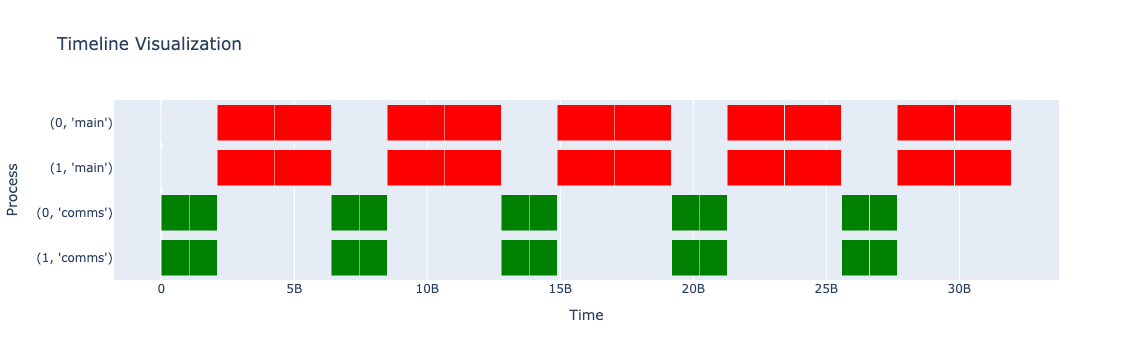

5


In [145]:
run_fsdp_with_delay(num_layers=5, fsdp_buffer_size=0)
from controller.simulator import simulate_commands, chrome_events, visualize_events, analyze_events
events = simulate_commands(device_mesh.ctrl.backend.worker_commands)
visualize_events(events)

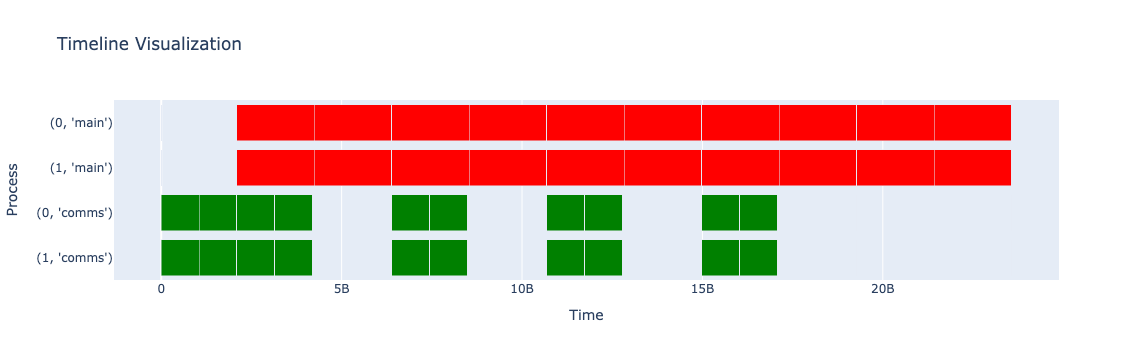

In [146]:
run_fsdp_with_delay(num_layers=5, fsdp_buffer_size=1)
from controller.simulator import simulate_commands, chrome_events, visualize_events, analyze_events
events = simulate_commands(device_mesh.ctrl.backend.worker_commands)
visualize_events(events)

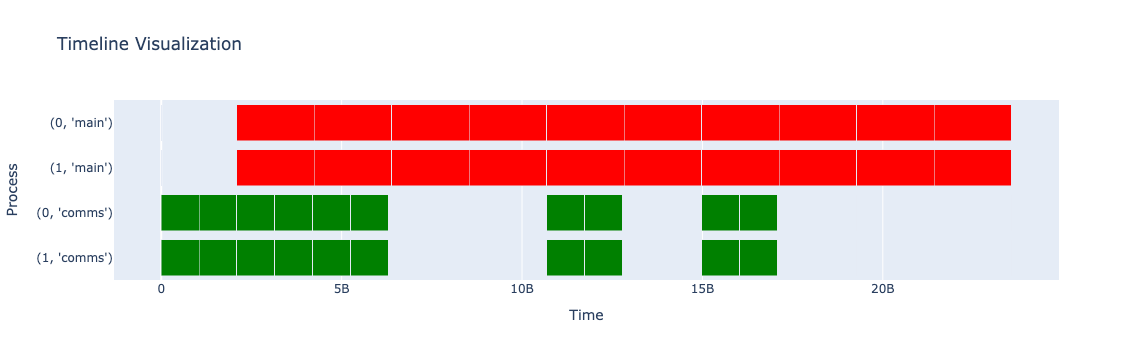

In [147]:
run_fsdp_with_delay(num_layers=5, fsdp_buffer_size=2)
from controller.simulator import simulate_commands, chrome_events, visualize_events, analyze_events
events = simulate_commands(device_mesh.ctrl.backend.worker_commands)
visualize_events(events)